<a href="https://colab.research.google.com/github/vaishnavi190124/ML-Practicals/blob/main/Basic_Decision_Tree_Classifier_Experiment_vaishnavi_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: Decision Tree Classifier

**Aim:** Train and visualize a decision tree classifier; analyze performance with/without pruning and depth control and demonstrate overfitting using synthetic data.

**Libraries:** NumPy, Matplotlib and Scikit-learn                                                                                                                    
Author: Dr. Priya B. Pandharbale

Run the following cells one by one.

## 1. Import libraries and create data

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Create simple synthetic data
X, y = make_moons(n_samples=300, noise=0.10, random_state=10)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=10
)

## 2. Display the dataset

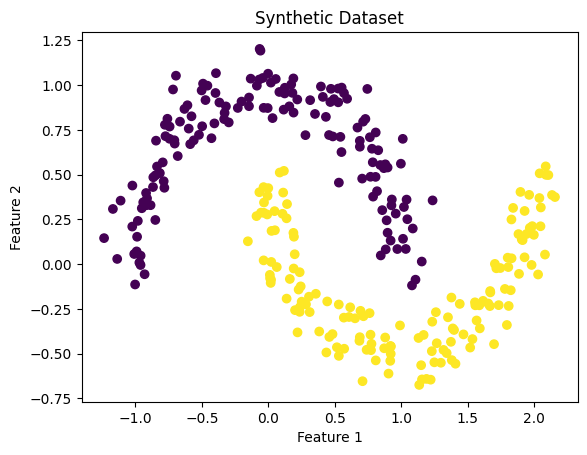

In [2]:
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Dataset")
plt.show()

## 3. Decision Tree without pruning

Training Accuracy: 1.0
Testing Accuracy: 1.0


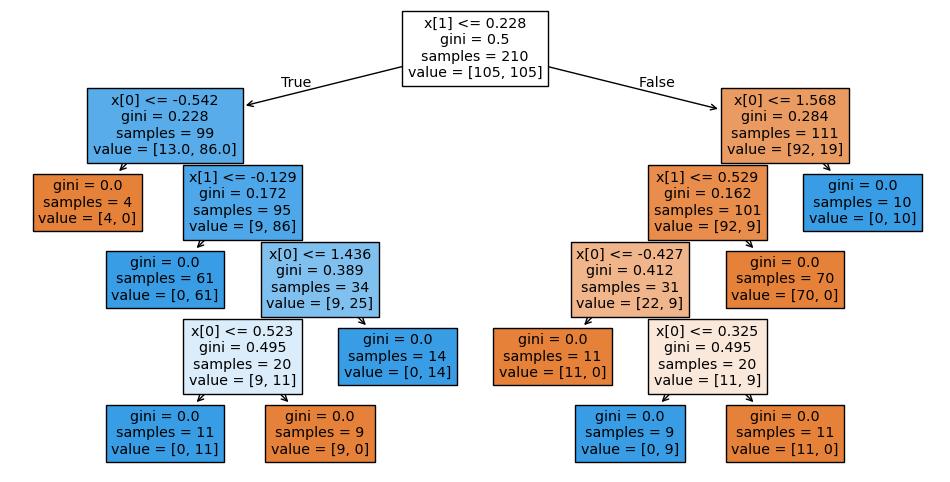

In [3]:
# Create and train the model
model1 = DecisionTreeClassifier(random_state=42)
model1.fit(X_train, y_train)

# Calculate accuracy
print("Training Accuracy:", accuracy_score(y_train, model1.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model1.predict(X_test)))

# Display decision tree
plt.figure(figsize=(12, 6))
plot_tree(model1, filled=True)
plt.show()

**Observation:** A tree without depth control may become very large. It can learn the training data too closely. This is called overfitting.

## 4. Decision Tree with depth control

Training Accuracy: 0.9142857142857143
Testing Accuracy: 0.9


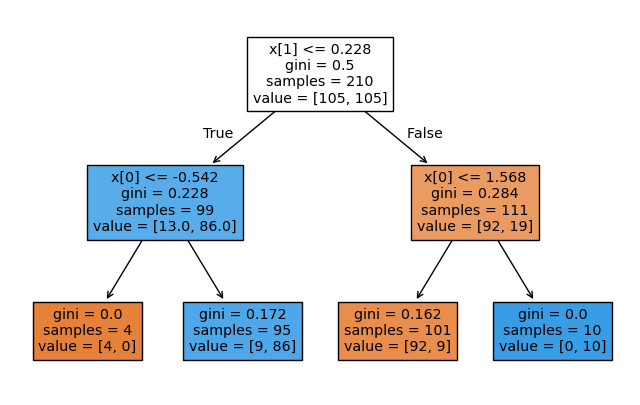

In [4]:
# Limit tree depth to 2
model2 = DecisionTreeClassifier(max_depth=2, random_state=42)
model2.fit(X_train, y_train)

print("Training Accuracy:", accuracy_score(y_train, model2.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model2.predict(X_test)))

plt.figure(figsize=(8, 5))
plot_tree(model2, filled=True)
plt.show()

**Observation:** `max_depth=2` creates a smaller tree and helps control overfitting.

## 5. Decision Tree with pruning

Training Accuracy: 1.0
Testing Accuracy: 1.0


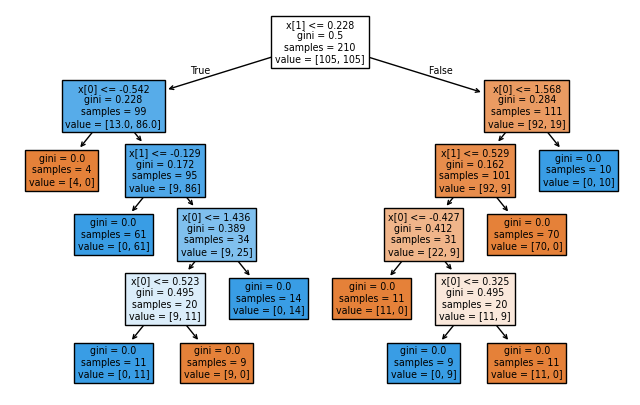

In [5]:
# Apply pruning
model3 = DecisionTreeClassifier(ccp_alpha=0.01, random_state=42)
model3.fit(X_train, y_train)

print("Training Accuracy:", accuracy_score(y_train, model3.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model3.predict(X_test)))

plt.figure(figsize=(8, 5))
plot_tree(model3, filled=True)
plt.show()

**Observation:** Pruning removes some branches and makes the tree simpler.

## 6. Compare the three models

In [6]:
print("Model             Training Accuracy     Testing Accuracy")

print("Without pruning  ",
      round(accuracy_score(y_train, model1.predict(X_train)), 2), "              ",
      round(accuracy_score(y_test, model1.predict(X_test)), 2))

print("Depth control    ",
      round(accuracy_score(y_train, model2.predict(X_train)), 2), "              ",
      round(accuracy_score(y_test, model2.predict(X_test)), 2))

print("With pruning     ",
      round(accuracy_score(y_train, model3.predict(X_train)), 2), "              ",
      round(accuracy_score(y_test, model3.predict(X_test)), 2))

Model             Training Accuracy     Testing Accuracy
Without pruning   1.0                1.0
Depth control     0.91                0.9
With pruning      1.0                1.0


## Result

The Decision Tree Classifier was trained using synthetic data. The tree was visualized and its performance was compared without pruning, with depth control and with pruning. The difference between training and testing accuracy was used to understand overfitting.